In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import re


def plot_H1_error(filename, convergence_order = None):
    # ============================================================
    # 1. Đọc file CSV
    # ============================================================
    df = pd.read_csv(
        filename,
        skipinitialspace=True
    )

    # Xóa khoảng trắng thừa trong tên cột
    df.columns = df.columns.str.strip()

    # ============================================================
    # 2. Kiểm tra các cột cần thiết
    # ============================================================
    required_columns = ["h", "H1 Error"]

    for col in required_columns:
        if col not in df.columns:
            raise ValueError(
                f"Không tìm thấy cột '{col}'.\n"
                f"Các cột hiện có: {df.columns.tolist()}"
            )

    # ============================================================
    # 3. Lấy dữ liệu
    # ============================================================
    h = df["h"].to_numpy()
    H1_error = df["H1 Error"].to_numpy()

    # ============================================================
    # 4. Xác định P1 hoặc P2 từ tên file
    # ============================================================
    match = re.search(
        r"P([12])",
        Path(filename).stem,
        re.IGNORECASE
    )

    if match is None:
        raise ValueError(
            "Tên file phải chứa P1 hoặc P2.\n"
            "Ví dụ: Ex1P1 RESULT.csv"
        )

    degree = int(match.group(1))

    # ============================================================
    # 5. Chọn bậc hội tụ lý thuyết
    # ============================================================
    if degree == 1:
        order = 1
        order_label = r"$O(h)$"
    else:
        order = 2
        order_label = r"$O(h^2)$"
    if convergence_order != None:
        order = convergence_order
        order_label = rf"$O(h^{{ {order} }})$"
    # ============================================================
    # 6. Tạo đường tham chiếu
    # ============================================================
    C = H1_error[0] / h[0]**order
    reference = C * h**order

    # ============================================================
    # 7. Vẽ đồ thị
    # ============================================================
    plt.figure(figsize=(8, 6))

    plt.loglog(
        h,
        H1_error,
        "o-",
        color="blue",
        linewidth=2,
        markersize=7,
        label=r"$\|u-u_h\|_{Y}$"
    )

    plt.loglog(
        h,
        reference,
        "--",
        color="red",
        linewidth=2,
        label=order_label
    )

    plt.xlabel(r"$h$", fontsize=14)
    plt.ylabel(r"$\|u - u_h\|_{Y}$", fontsize=14)

#    plt.title(
#        rf"$H^1$ Error Convergence - $P{degree}$",
#        fontsize=15
#    )

    plt.grid(
        True,
        which="both",
        linestyle="--",
        alpha=0.5
    )

    plt.legend(fontsize=12)

    plt.tight_layout()

    # ============================================================
    # 8. Lưu ảnh
    # ============================================================
    output_filename = Path(filename).with_suffix(".png")

    plt.savefig(
        output_filename,
        dpi=300,
        bbox_inches="tight"
    )

    print(f"Đã lưu hình: {output_filename}")

    # ============================================================
    # 9. Hiển thị
    # ============================================================
    plt.show()


def plot_relative_H1_error(filename, convergence_order = None):
    # ============================================================
    # 1. Đọc file CSV
    # ============================================================
    df = pd.read_csv(
        filename,
        skipinitialspace=True
    )

    # Xóa khoảng trắng thừa trong tên cột
    df.columns = df.columns.str.strip()

    # ============================================================
    # 2. Kiểm tra các cột cần thiết
    # ============================================================
    required_columns = ["h", "Relative H1 Error"]

    for col in required_columns:
        if col not in df.columns:
            raise ValueError(
                f"Không tìm thấy cột '{col}'.\n"
                f"Các cột hiện có: {df.columns.tolist()}"
            )

    # ============================================================
    # 3. Lấy dữ liệu
    # ============================================================
    h = df["h"].to_numpy()
    H1_error = df["Relative H1 Error"].to_numpy()

    # ============================================================
    # 4. Xác định P1 hoặc P2 từ tên file
    # ============================================================
    match = re.search(
        r"P([12])",
        Path(filename).stem,
        re.IGNORECASE
    )

    if match is None:
        raise ValueError(
            "Tên file phải chứa P1 hoặc P2.\n"
            "Ví dụ: Ex1P1 RESULT.csv"
        )

    degree = int(match.group(1))

    # ============================================================
    # 5. Chọn bậc hội tụ lý thuyết
    # ============================================================
    if degree == 1:
        order = 1
        order_label = r"$O(h)$"
    else:
        order = 2
        order_label = r"$O(h^2)$"
    if convergence_order != None:
        order = convergence_order
        order_label = rf"$O(h^{{ {order} }})$"
    # ============================================================
    # 6. Tạo đường tham chiếu
    # ============================================================
    C = H1_error[0] / h[0]**order
    reference = C * h**order

    # ============================================================
    # 7. Vẽ đồ thị
    # ============================================================
    plt.figure(figsize=(8, 6))

    plt.loglog(
        h,
        H1_error,
        "o-",
        color="blue",
        linewidth=2,
        markersize=7,
        label=r"$\tilde{E}_u$"
    )

    plt.loglog(
        h,
        reference,
        "--",
        color="red",
        linewidth=2,
        label=order_label
    )

    plt.xlabel(r"$h$", fontsize=14)
    plt.ylabel(r"$\|u - u_h\|_{Y}$", fontsize=14)

#    plt.title(
#        rf"$H^1$ Error Convergence - $P{degree}$",
#        fontsize=15
#    )

    plt.grid(
        True,
        which="both",
        linestyle="--",
        alpha=0.5
    )

    plt.legend(fontsize=12)

    plt.tight_layout()

    # ============================================================
    # 8. Lưu ảnh
    # ============================================================
    output_filename = Path(filename).with_suffix(".png")

    plt.savefig(
        output_filename,
        dpi=300,
        bbox_inches="tight"
    )

    print(f"Đã lưu hình: {output_filename}")

    # ============================================================
    # 9. Hiển thị
    # ============================================================
    plt.show()




Đã lưu hình: Example1\Ex1_kappa_1e-2_P1 RESULT.png


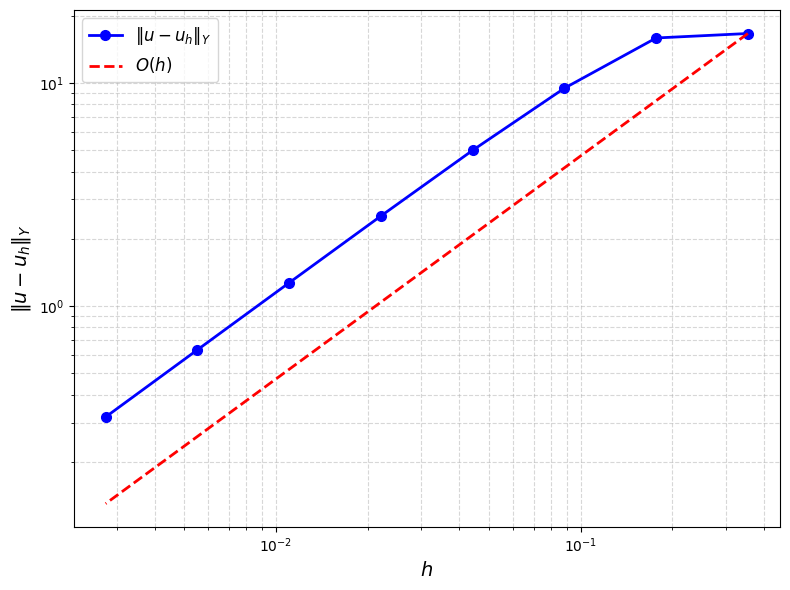

Đã lưu hình: Example1\Ex1_kappa_1e-2_P2 RESULT.png


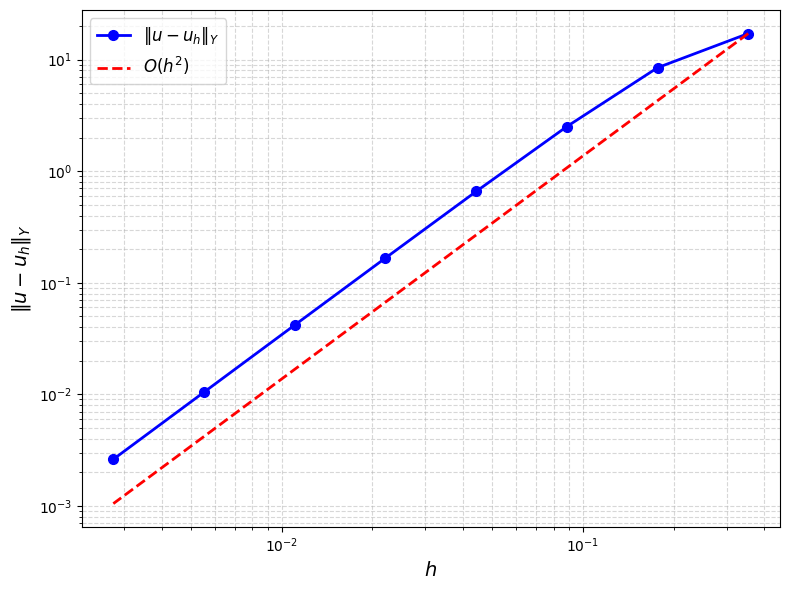

Đã lưu hình: Example1\Ex1_kappa_0.2_1e-2_P1 RESULT.png


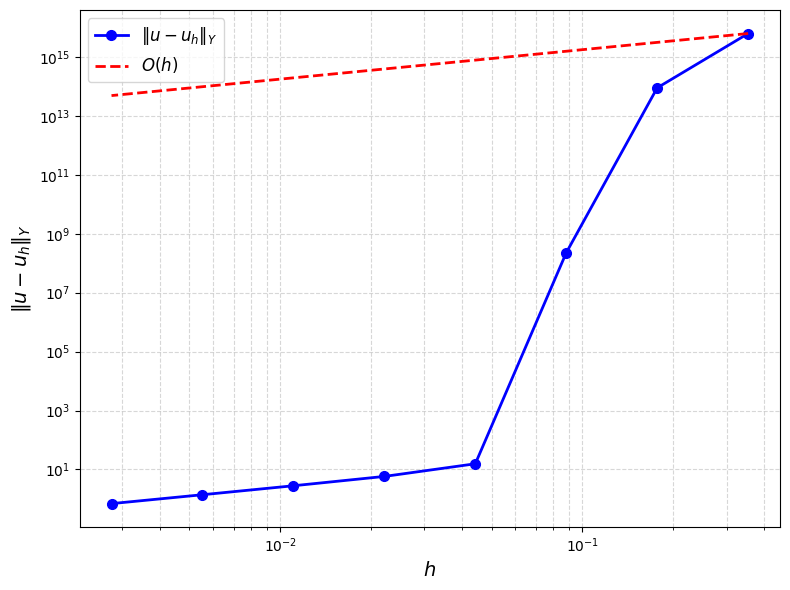

Đã lưu hình: Example1\Ex1_kappa_0.2_1e-2_P2 RESULT.png


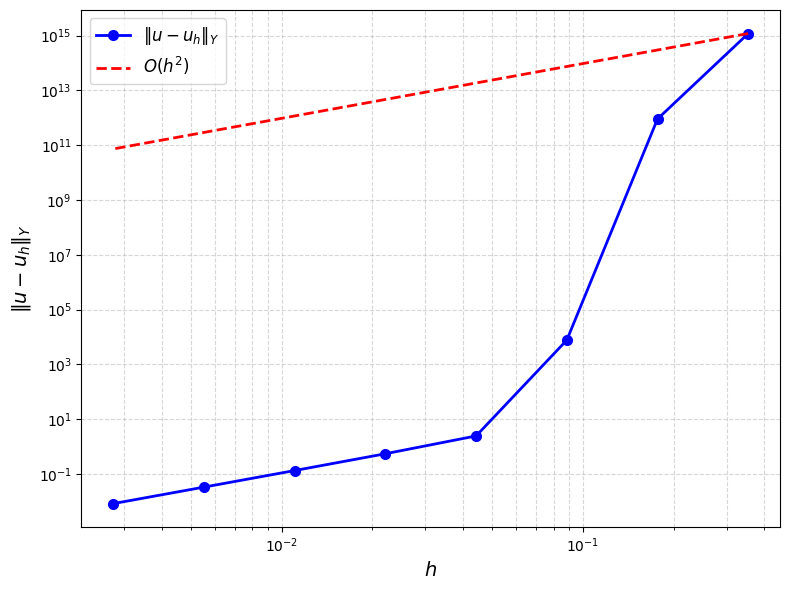

Đã lưu hình: Example1\Ex1_kappa_1e-3_P1 RESULT.png


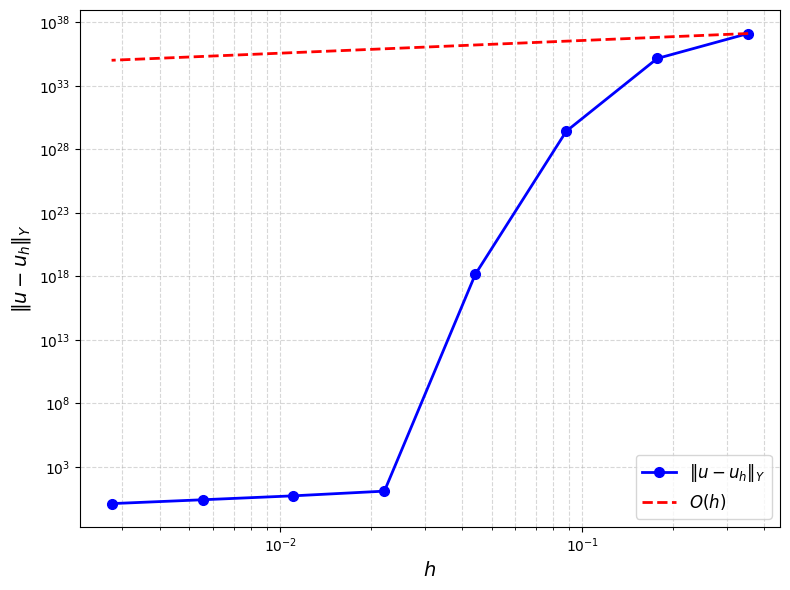

Đã lưu hình: Example1\Ex1_kappa_1e-3_P2 RESULT.png


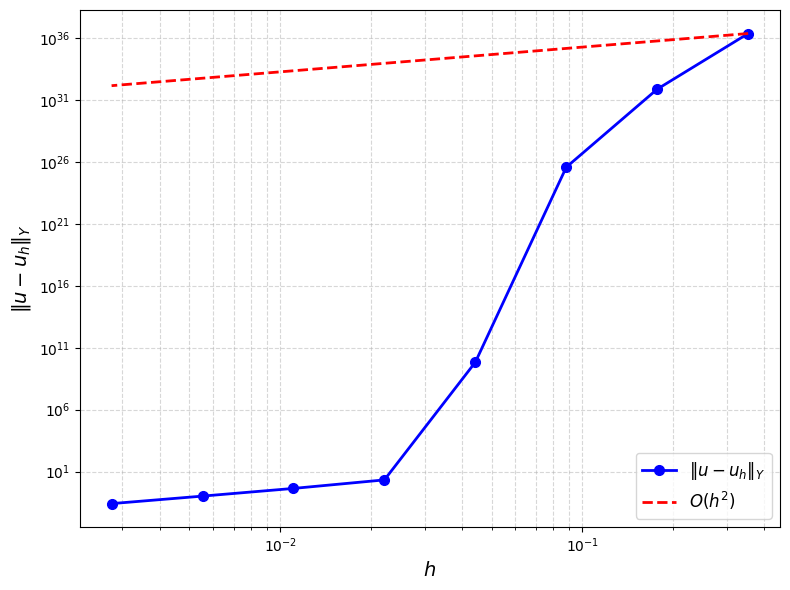

In [4]:
plot_H1_error("Example1/Ex1_kappa_1e-2_P1 RESULT.csv")
plot_H1_error("Example1/Ex1_kappa_1e-2_P2 RESULT.csv")
plot_H1_error("Example1/Ex1_kappa_0.2_1e-2_P1 RESULT.csv")
plot_H1_error("Example1/Ex1_kappa_0.2_1e-2_P2 RESULT.csv")
plot_H1_error("Example1/Ex1_kappa_1e-3_P1 RESULT.csv")
plot_H1_error("Example1/Ex1_kappa_1e-3_P2 RESULT.csv")

In [17]:
import pandas as pd

df = pd.read_csv(
    "Ex1P1 RESULT.csv",
    skipinitialspace=True
)

df.columns = df.columns.str.strip()

print(df.columns.tolist())
print(df.head())


['N', 'h', 'L2 Error', 'L2 EOC', 'H1 Error', 'H1 EOC']
    N         h  L2 Error   L2 EOC  H1 Error    H1 EOC
0   4  0.353553  0.071587  0.00000  0.617690  0.000000
1   8  0.176777  0.019670  1.86367  0.307422  1.006660
2  16  0.088388  0.005118  1.94229  0.153981  0.997469
3  32  0.044194  0.001298  1.97916  0.077059  0.998715
4  64  0.022097  0.000325  1.99902  0.038544  0.999445


Đã lưu hình: LimitedRegularity\LimitedRegularity_P1_RESULT.png


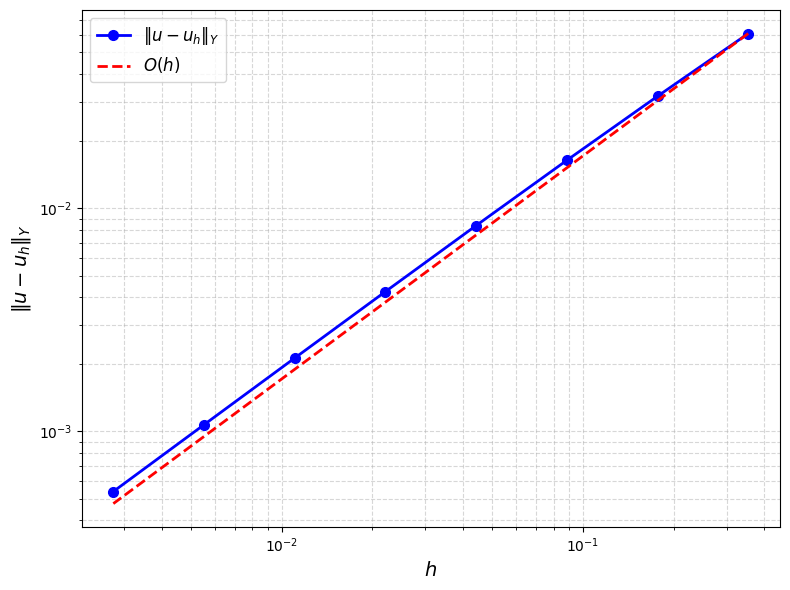

Đã lưu hình: LimitedRegularity\LimitedRegularity_P2_RESULT.png


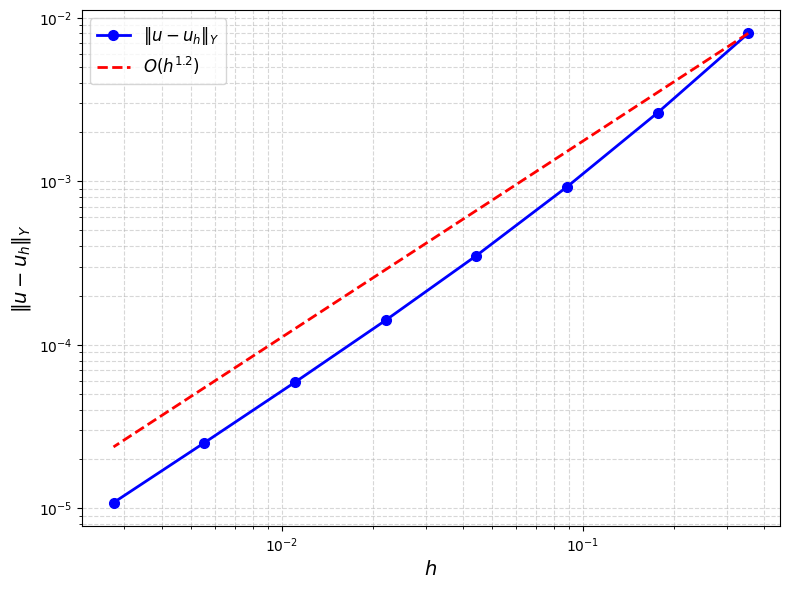

In [4]:
plot_H1_error("LimitedRegularity/LimitedRegularity_P1_RESULT.csv")
plot_H1_error("LimitedRegularity/LimitedRegularity_P2_RESULT.csv", convergence_order = 1.2)

Đã lưu hình: Singular\Singular_P1_RESULT.png


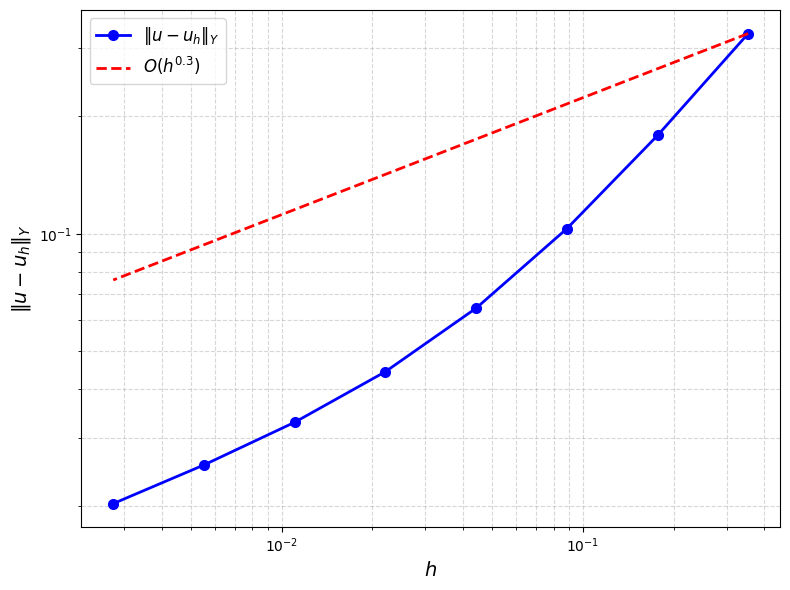

Đã lưu hình: Singular\Singular_P2_RESULT.png


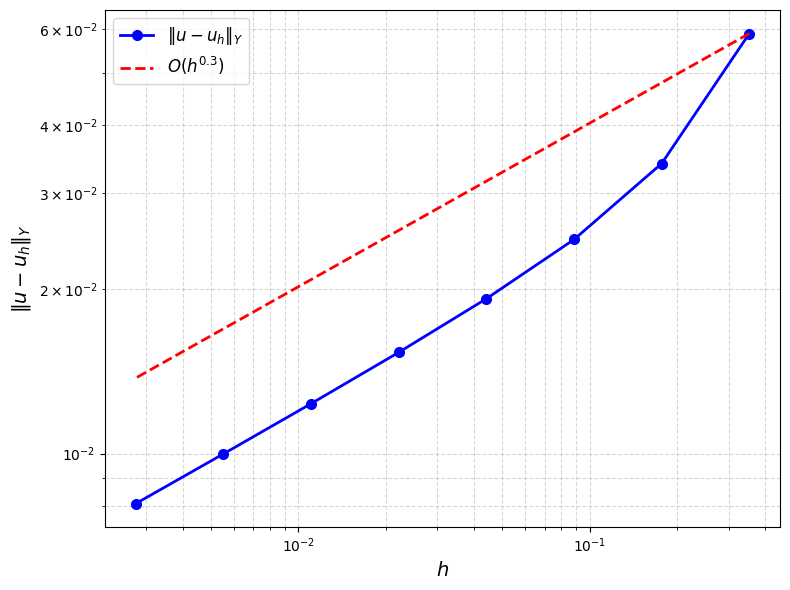

In [5]:
plot_H1_error("Singular/Singular_P1_RESULT.csv", convergence_order = 0.3)
plot_H1_error("Singular/Singular_P2_RESULT.csv", convergence_order = 0.3)

Đã lưu hình: Example2Dimension\Example2Dimension_P1_RESULT.png


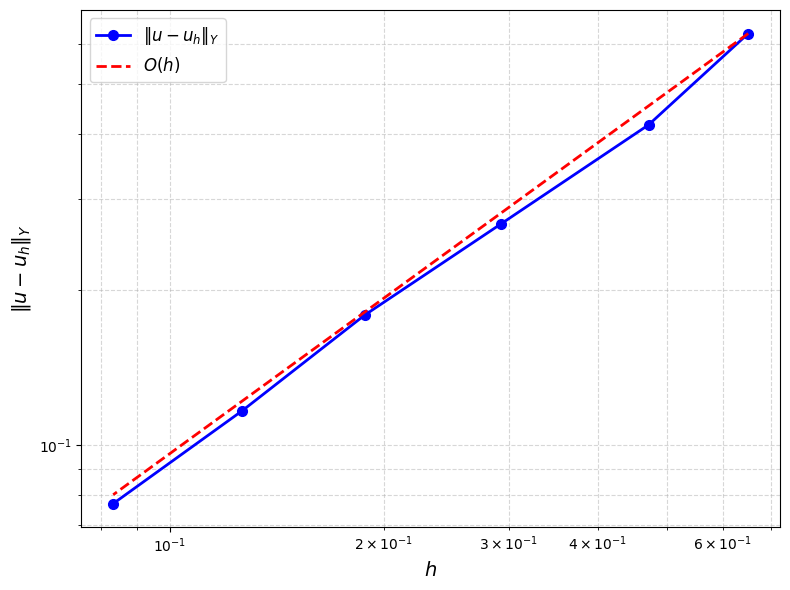

Đã lưu hình: Example2Dimension\Example2Dimension_P2_RESULT.png


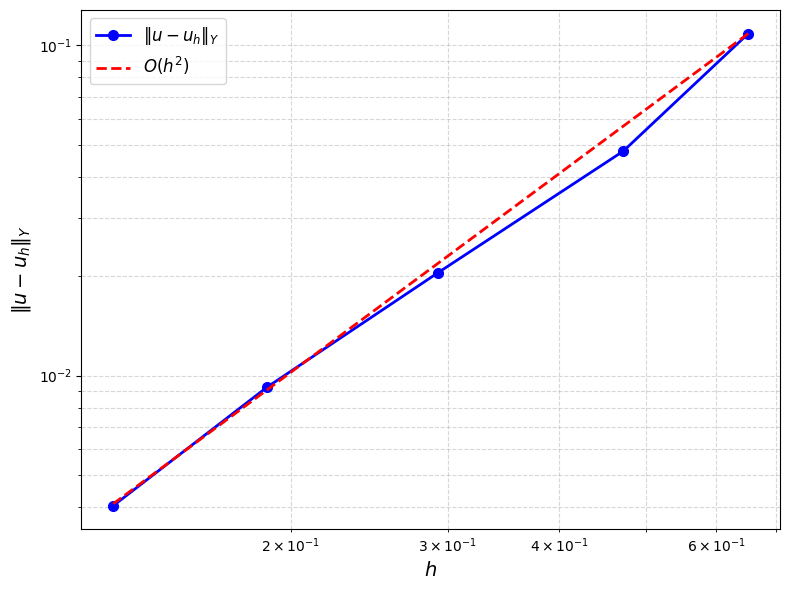

In [6]:
plot_H1_error("Example2Dimension/Example2Dimension_P1_RESULT.csv")
plot_H1_error("Example2Dimension/Example2Dimension_P2_RESULT.csv")


Đã lưu hình: Ex2dP1 RESULT.png


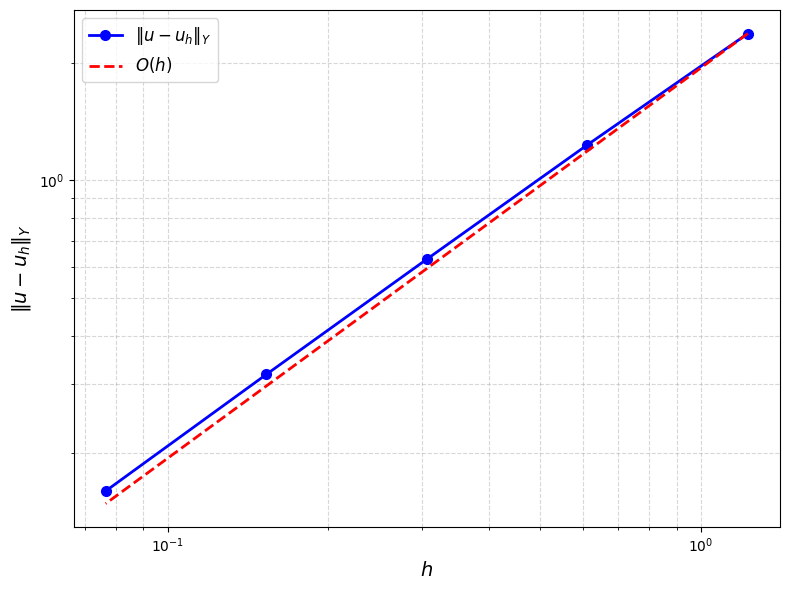

Đã lưu hình: Ex2dP2 RESULT.png


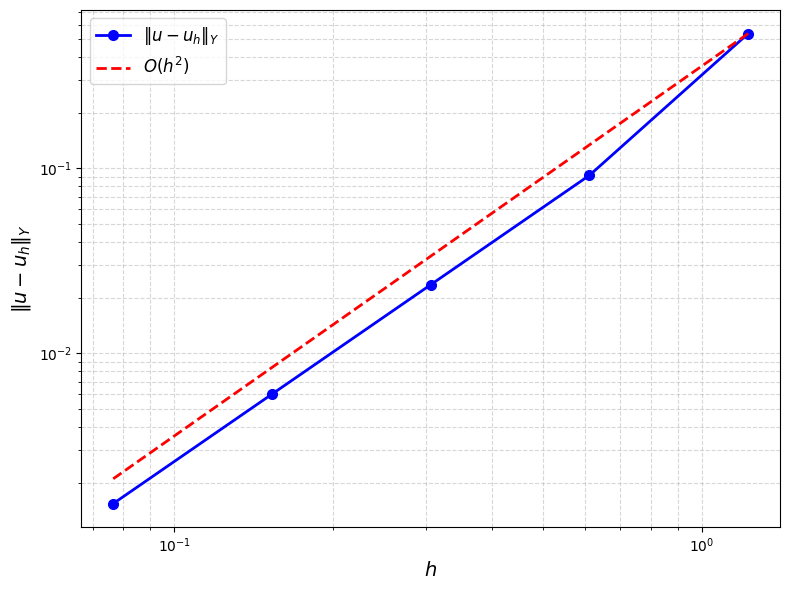

In [2]:
plot_H1_error("Ex2dP1 RESULT.csv")
plot_H1_error("Ex2dP2 RESULT.csv")

Đã lưu hình: Ex_not_smooth_P1 RESULT.png


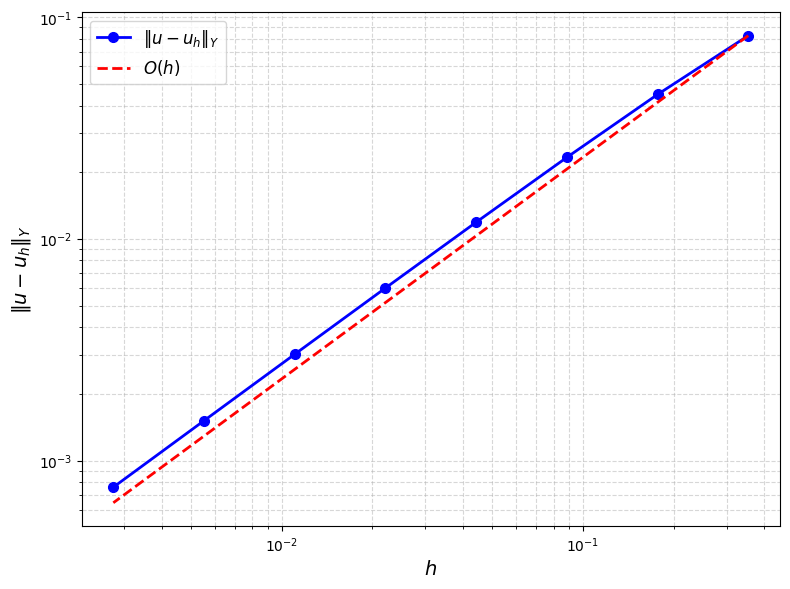

Đã lưu hình: Ex_not_smooth_P2 RESULT.png


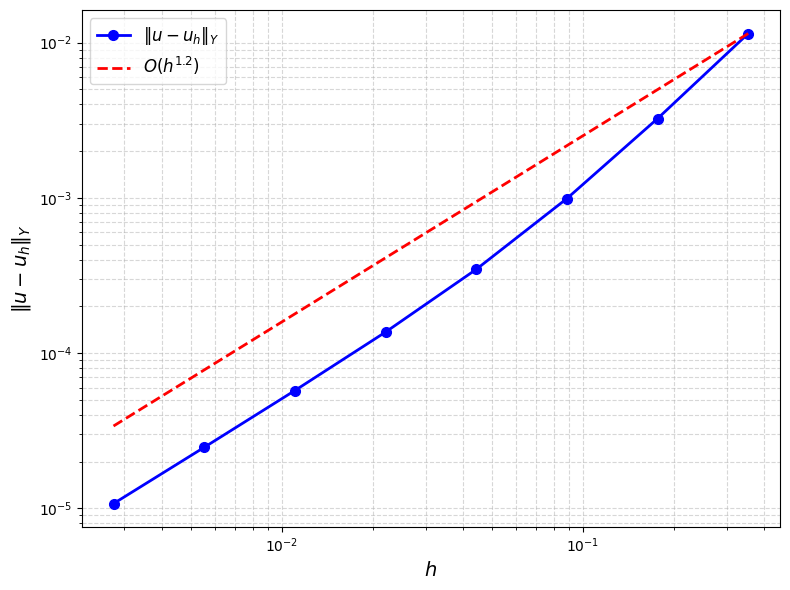

In [15]:
plot_H1_error("Ex_not_smooth_P1 RESULT.csv")
plot_H1_error("Ex_not_smooth_P2 RESULT.csv", convergence_order=1.2)

Đã lưu hình: Ex_u0_in_L2_not_H1_P1 RESULT.png


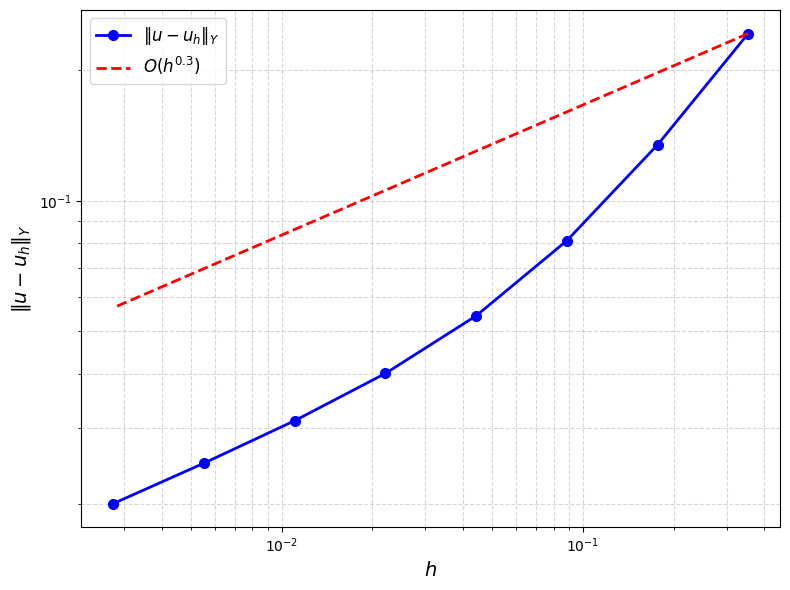

Đã lưu hình: Ex_u0_in_L2_not_H1_P2 RESULT.png


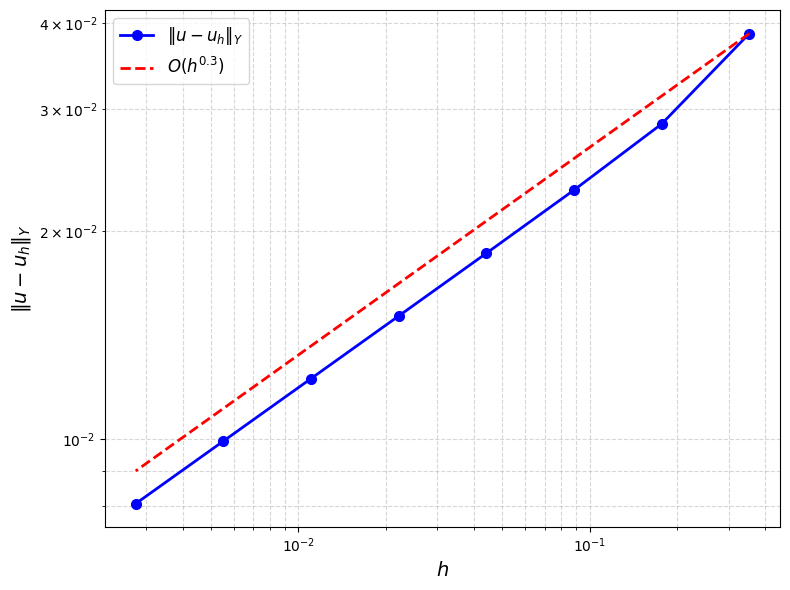

In [16]:
plot_H1_error("Ex_u0_in_L2_not_H1_P1 RESULT.csv", convergence_order=0.3)
plot_H1_error("Ex_u0_in_L2_not_H1_P2 RESULT.csv", convergence_order=0.3)

Đã lưu hình: Ex_not_exact_solution_P1_RESULT.png


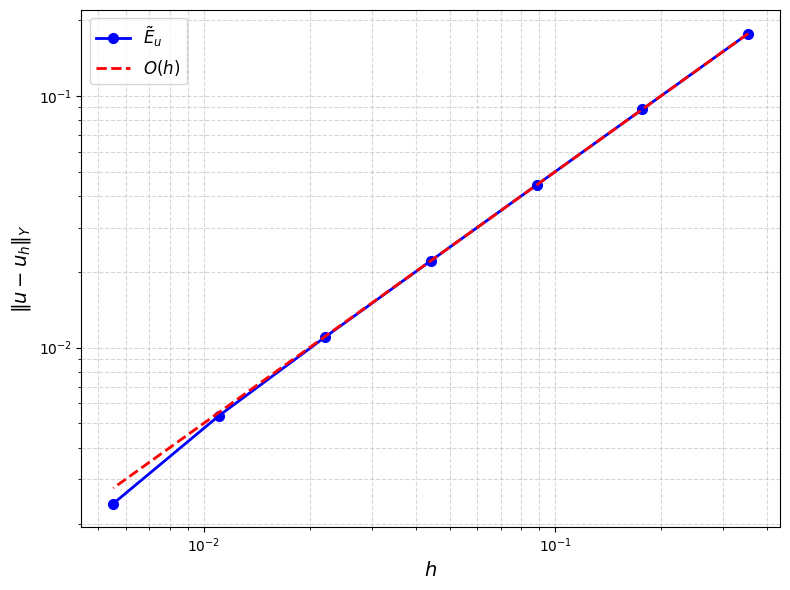

Đã lưu hình: Ex_not_exact_solution_P2_RESULT.png


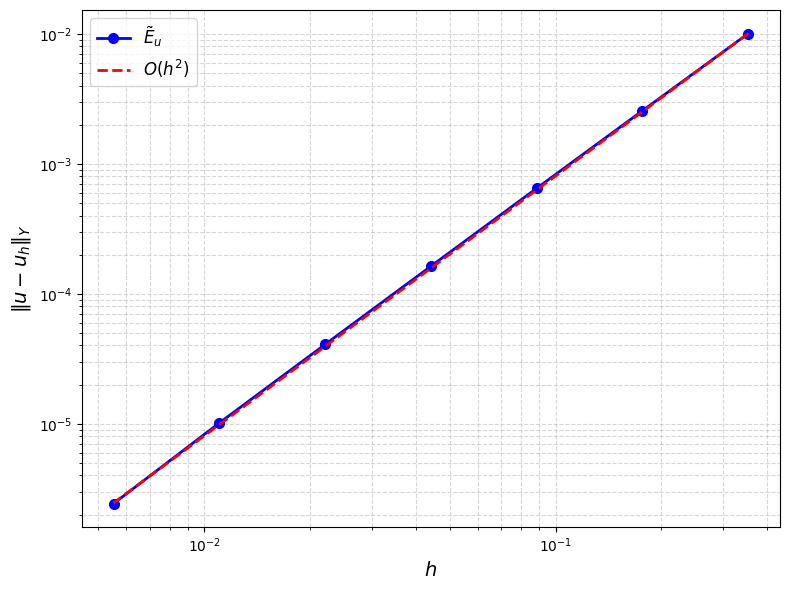

In [13]:
plot_relative_H1_error("Ex_not_exact_solution_P1_RESULT.csv")
plot_relative_H1_error("Ex_not_exact_solution_P2_RESULT.csv")


Đã lưu hình: Ex_draftP1 RESULT.png


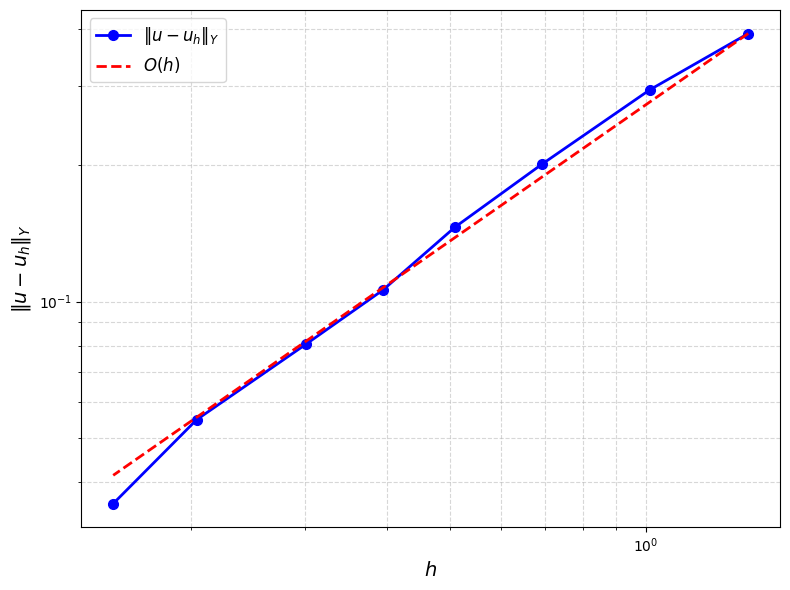

Đã lưu hình: Ex_draftP2 RESULT.png


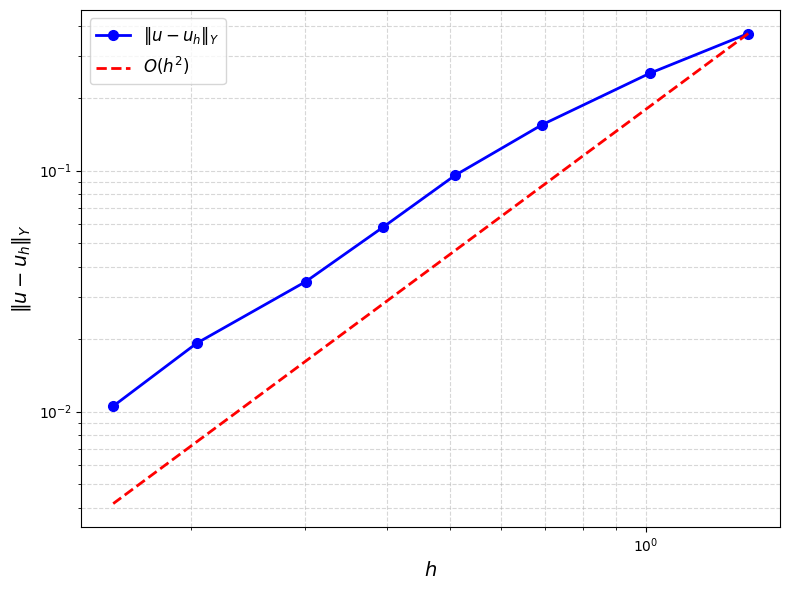

In [2]:
plot_H1_error("Ex_draftP1 RESULT.csv")
plot_H1_error("Ex_draftP2 RESULT.csv")

Đã lưu hình: Ex2d_Ellipse_RESULT P1.png


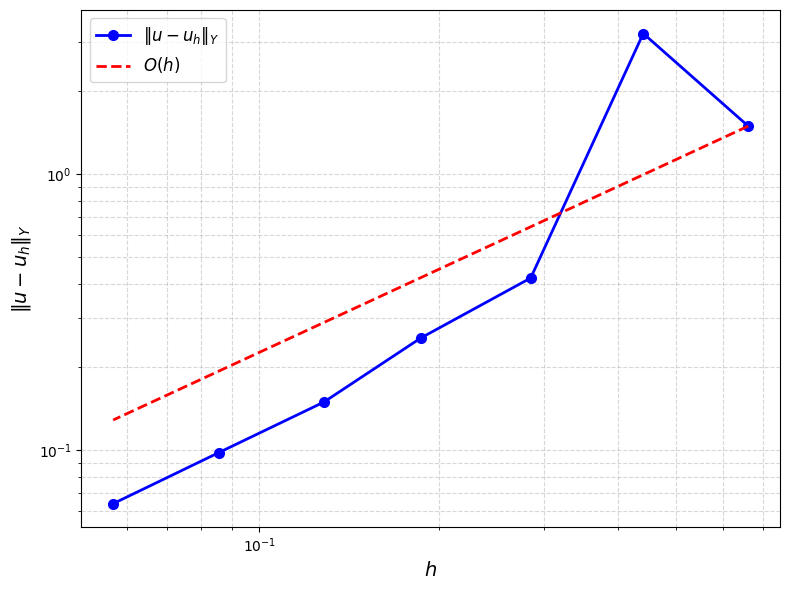

Đã lưu hình: Ex2d_Ellipse_RESULT P2.png


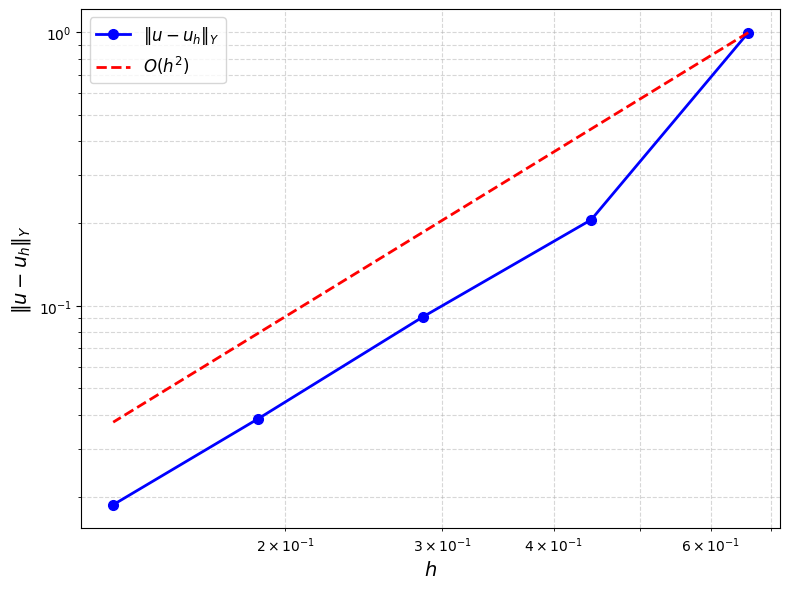

In [5]:
plot_H1_error("Ex2d_Ellipse_RESULT P1.csv")
plot_H1_error("Ex2d_Ellipse_RESULT P2.csv")

Đã lưu hình: WithoutExactSolution\ExNotExactSol_P1 RESULT.png


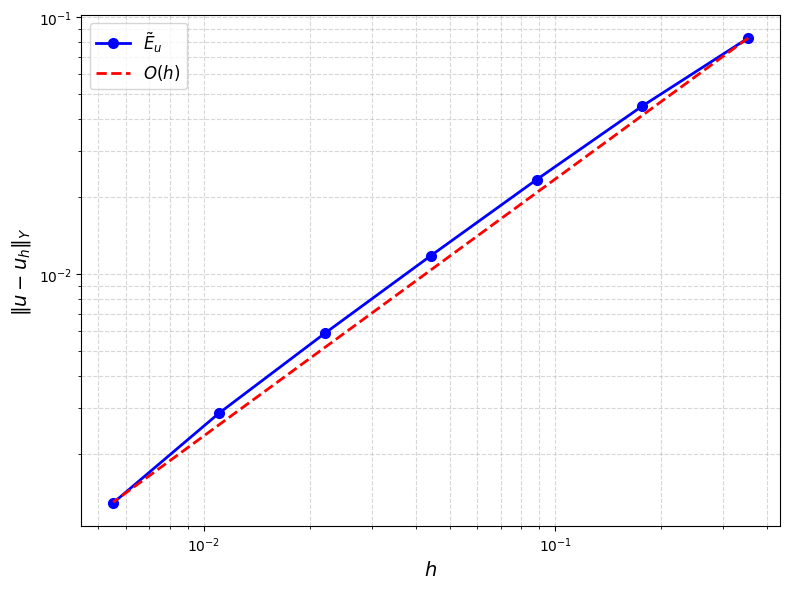

Đã lưu hình: WithoutExactSolution\ExNotExactSol_P2 RESULT.png


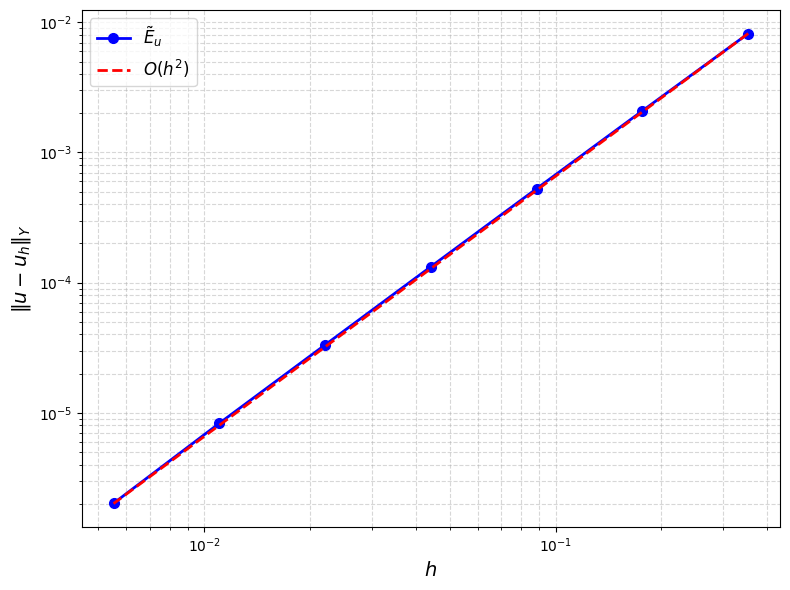

In [6]:
plot_relative_H1_error("WithoutExactSolution/ExNotExactSol_P1 RESULT.csv")
plot_relative_H1_error("WithoutExactSolution/ExNotExactSol_P2 RESULT.csv")